In [2]:
!pip install numpy pandas matplotlib seaborn scikit-learn tensorflow


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [4]:
print("TensorFlow Version:",tf.__version__)

TensorFlow Version: 2.22.0-rc0


In [5]:
# Load the iris dataset 
iris = load_iris()

# Store input features
X = iris.data

# Store target output
y = iris.target 

# Display dataset loading message 
print("Iris Dataset Loaded Successfully!")

Iris Dataset Loaded Successfully!


In [6]:
# Convert dataset into DataFrame 
df = pd.DataFrame(iris.data,columns=iris.feature_names)

# Add target column 
df["Species"] = iris.target 

# Display first five records 
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [7]:
# Check number of rows and columns 
print("Dataset Shape:", df.shape)

# Check total rows 
print("Total Records :", df.shape[0])

# Check total columns 
print("Total Columns:", df.shape[1])

Dataset Shape: (150, 5)
Total Records : 150
Total Columns: 5


In [8]:
# Display information about dataset 
print("Dataset Information:")

df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   Species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [9]:
# Check missing values in each column 
print("Missing Values in Dataset:")

print(df.isnull().sum())

Missing Values in Dataset:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
Species              0
dtype: int64


In [10]:
# Count the number of flowers in each species 
print("Species Count:")

print(df["Species"].value_counts())

Species Count:
Species
0    50
1    50
2    50
Name: count, dtype: int64


In [11]:
# Display actual species names
print("Species Names:")

print(iris.target_names)

Species Names:
['setosa' 'versicolor' 'virginica']


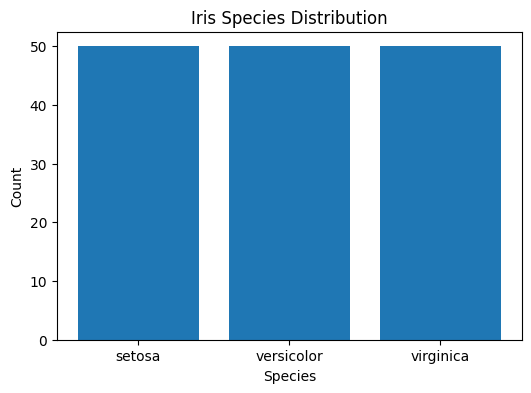

In [12]:
# Count each flower species 
species_count = df["Species"].value_counts()

# Create bar chart
plt.figure(figsize=(6,4))

plt.bar(iris.target_names, species_count.sort_index())

plt.title("Iris Species Distribution")
plt.xlabel("Species")
plt.ylabel("Count")

plt.show()

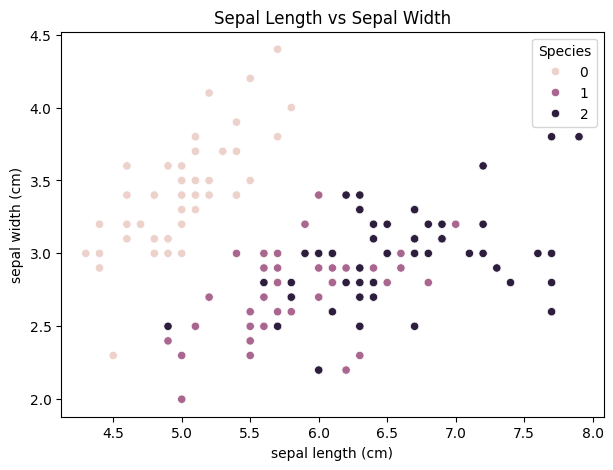

In [13]:
# Create scatter plot
plt.figure(figsize=(7,5))

sns.scatterplot(data=df, x="sepal length (cm)", y="sepal width (cm)", hue="Species")

plt.title("Sepal Length vs Sepal Width")

plt.show()
                

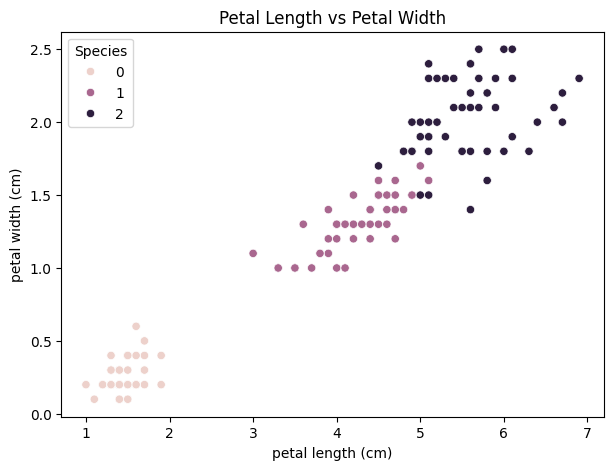

In [14]:
# Create scatter plot
plt.figure(figsize=(7, 5))

sns.scatterplot(data=df,x="petal length (cm)", y="petal width (cm)", hue="Species")

plt.title("Petal Length vs Petal Width")

plt.show()

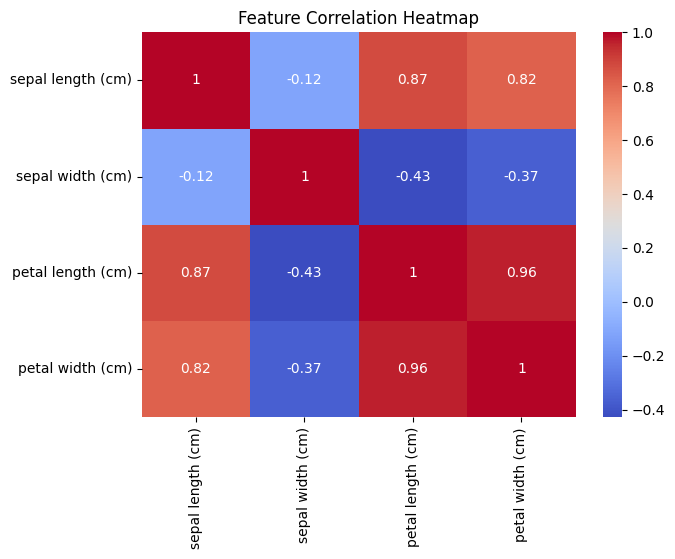

In [15]:
# Calculate correlation between numerical coulumns
correlation = df.drop("Species", axis=1).corr()

# Dispaly heatmap
plt.figure(figsize=(7,5))

sns.heatmap(correlation, annot=True, cmap="coolwarm")

plt.title("Feature Correlation Heatmap")

plt.show()



In [16]:
# Separate input features
X = df.drop("Species", axis=1)

# Store target variable
y = df["Species"]

# Display shapes
print("Input Shape:", X.shape)
print("Output Shape:", y.shape)

Input Shape: (150, 4)
Output Shape: (150,)


In [17]:
# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42, stratify=y)

In [18]:
# Display shapes
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:",y_train.shape)
print("Testing Target:",y_test.shape)

Training Data: (120, 4)
Testing Data: (30, 4)
Training Target: (120,)
Testing Target: (30,)


In [19]:
# Create StandardScaler object
scaler = StandardScaler()

# Fit and transform training data 
X_train = scaler.fit_transform(X_train)

# Transform testing data
X_test = scaler.transform(X_test)

print("Feature Scaling Completed!")

Feature Scaling Completed!


In [20]:
# Create FNN model
model = keras.Sequential()

# Add input layer
model.add(layers.Input(shape=(4,)))

# Add first hidden layer
model.add(layers.Dense(16, activation="relu"))

# Add second hidden layer
model.add(layers.Dense(8,activation="relu"))

# Add output layer
model.add(layers.Dense(3,activation="softmax"))

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 16)                  │              80 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 3)                   │              27 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

In [21]:
# Compile the FNN model
model.compile(optimizer="adam", loss=keras.losses.SparseCategoricalCrossentropy(), metrics=["accuracy"])

print("Model Compiled Successfully!")

Model Compiled Successfully!


In [22]:
# Train the FNN model
history = model.fit(X_train, y_train, epochs=50, batch_size=8, validation_split=0.2, verbose=1)

print("Model Training Completed!")

Epoch 1/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.0104 - loss: 1.2305 - val_accuracy: 0.0833 - val_loss: 1.1558
Epoch 2/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.0417 - loss: 1.1612 - val_accuracy: 0.2917 - val_loss: 1.1022
Epoch 3/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1667 - loss: 1.1088 - val_accuracy: 0.3750 - val_loss: 1.0656
Epoch 4/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4167 - loss: 1.0691 - val_accuracy: 0.7083 - val_loss: 1.0411
Epoch 5/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6458 - loss: 1.0357 - val_accuracy: 0.7083 - val_loss: 1.0192
Epoch 6/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7292 - loss: 1.0064 - val_accuracy: 0.7500 - val_loss: 0.9960
Epoch 7/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7917 - loss: 0.9778 - val_accuracy: 0.7500 - val_loss: 0.9714
Epoch 8/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8021 - loss: 0.9487 - val_accuracy: 0.7500 - val_lo

<function matplotlib.pyplot.show(close=None, block=None)>

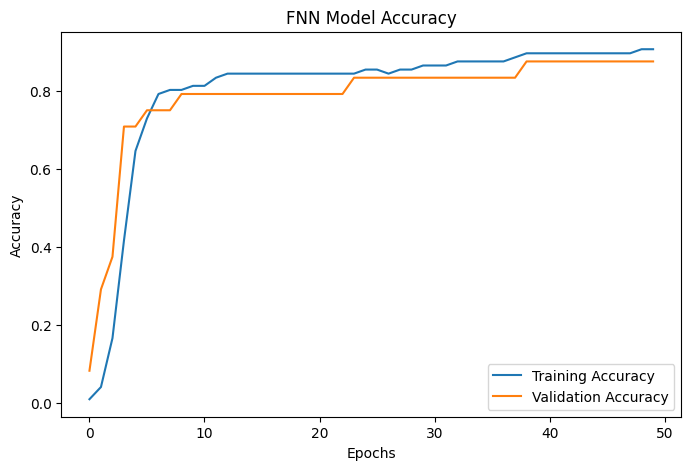

In [23]:
# Plot training and validation accuracy

plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"], label="Training Accuracy")

plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("FNN Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.show

In [24]:
# Evaluate model on test data

test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy Percentage:", test_accuracy * 100)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 220ms/step - accuracy: 0.8000 - loss: 0.3376
Test Loss: 0.337576687335968
Test Accuracy: 0.800000011920929
Test Accuracy Percentage: 80.0000011920929


In [25]:
# Predict output for test data
y_pred = model.predict(X_test)

# Convert probabilities into class labels
y_pred_classes = np.argmax(y_pred,axis=1)

print("Actual Values:")
print(y_test.values)

print("\nPredicted Values:")
print(y_pred_classes)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
Actual Values:
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

Predicted Values:
[0 2 1 1 0 2 0 0 2 1 2 2 2 2 0 0 0 1 1 2 0 2 2 1 2 2 2 0 2 0]


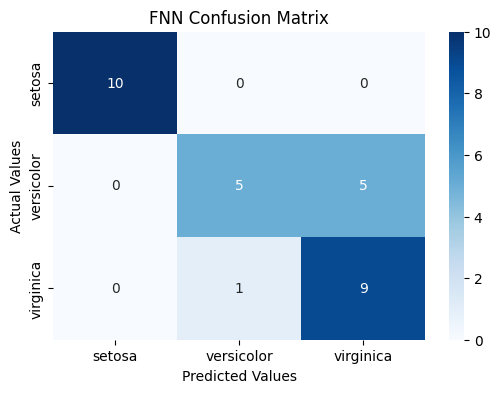

In [26]:
# Calculate Confusion matrix
cm = confusion_matrix(y_test, y_pred_classes)

# Display confusion matrix
plt.figure(figsize=(6,4))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=iris.target_names, yticklabels=iris.target_names)

plt.title("FNN Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

In [27]:
# Generate classification report
report = classification_report(y_test,y_pred_classes,target_names=iris.target_names)

# Display report
print("Classification Report:")
print(report)

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      0.50      0.62        10
   virginica       0.64      0.90      0.75        10

    accuracy                           0.80        30
   macro avg       0.83      0.80      0.79        30
weighted avg       0.83      0.80      0.79        30



In [29]:
# Create new flower data
new_flower = pd.DataFrame([[5.1, 3.5, 1.4, 0.2]],columns=iris.feature_names)

# Apply feature scaling
new_flower_scaled = scaler.transform(new_flower)

# Predict flower species
prediction =model.predict(new_flower_scaled)

# Get predicted class
predicted_class = np.argmax(prediction, axis=1)

# Display result
print("Predicted Flower:",iris.target_names[predicted_class[0]])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
Predicted Flower: setosa


In [30]:
# Save the trained FNN model
model.save("iris_fnn_model.keras")

print("FNN Model Saved Successfully!")

FNN Model Saved Successfully!


In [31]:
# Import joblib
import joblib

# Save the scaler
joblib.dump(scaler,"iris_scaler.pkl")

print("Scaler Saved Successfully!")

Scaler Saved Successfully!
